# Sinhala Hate-Speech Detection with Multinomial Naive Bayes

This notebook trains a leakage-safe MNB text classifier on the clean SOLD training split and evaluates it on the clean and generated noisy test sets. It uses one scikit-learn `Pipeline`, preventing unfitted-vectorizer and double-vectorization errors. Run the notebook from top to bottom.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score,
    precision_recall_fscore_support
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline

RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 120)
print('Imports complete.')

Imports complete.


## Locate the repository

For Colab, clone/upload the repository and set `PROJECT_ROOT` manually if automatic discovery does not find it.

In [2]:
def find_project_root(start=Path.cwd()):
    candidates = [start, *start.parents]
    candidates += [Path('/content/Sinhala-Noisy-Hatespeech-Data')]
    for candidate in candidates:
        if (candidate / 'data' / 'sold' / 'train.jsonl').is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        'Could not find data/sold/train.jsonl. Set PROJECT_ROOT to the repository directory.'
    )

PROJECT_ROOT = find_project_root()
DATA_ROOT = PROJECT_ROOT / 'data'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'mnb'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_ROOT)

Project root: E:\nlp\Sinhala-Noisy-Hatespeech-Data


## Load and validate data

In [3]:
def load_jsonl(path, required_columns):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    df = pd.read_json(path, lines=True)
    missing = set(required_columns) - set(df.columns)
    if missing:
        raise ValueError(f'{path} is missing columns {sorted(missing)}; found {df.columns.tolist()}')
    if df.empty:
        raise ValueError(f'{path} contains no rows')
    return df

train_df = load_jsonl(DATA_ROOT / 'sold' / 'train.jsonl', {'text', 'label'})
clean_test_df = load_jsonl(DATA_ROOT / 'sold' / 'test.jsonl', {'text', 'label'})

train_df = train_df.dropna(subset=['label']).copy()
clean_test_df = clean_test_df.dropna(subset=['label']).copy()
train_df['text'] = train_df['text'].fillna('').astype(str)
clean_test_df['text'] = clean_test_df['text'].fillna('').astype(str)

if train_df['label'].nunique() < 2:
    raise ValueError('Training data must contain at least two label classes.')

print(f'Train rows: {len(train_df):,}; clean test rows: {len(clean_test_df):,}')
display(train_df['label'].value_counts(dropna=False).rename('count').to_frame())
display(train_df[['text', 'label']].head())

Train rows: 7,500; clean test rows: 2,500


,count
label,
0,4324
1,3176


,text,label
0,@USER @USER පට්ට පට පට...,0
1,"පරණ කෑල්ල අද වෙනකම් හිටියනම් අදට අවුරුදු 4යි. යාලු වෙලා. වෙලාවට ඊට පහු වෙනිදම බූට් එක කෑවෙ, නැත්තම් අවුරුදු 4ක් එක ක...",1
2,යාළුවා කියලා හිතන් සර් ගේ ඔලුවට රෙද්ද දාලා නෙලන එක වෙනමම ආතල් එකක් බන්. #childhoodmemories URL This Tweet is unavai...,0
3,හොඳ මිතුරියක් කතා කලා. විස්තර කතාකරමින් ඉදලා මේ දවස්වල මොකො කරන්නේ ඇහුවා. මම උයපු හදපු කෑම බීම ජාති කිව්වා. බැඳලත් න...,1
4,"ඔය බනින්නෙ.. හරකා, මී හරකා කිය කිය...",1


## Define the model

A fresh pipeline is created for every condition. Each vectorizer is therefore fitted only on its matching training split. The full pipeline always accepts raw strings.

In [4]:
def build_mnb_pipeline():
    features = FeatureUnion([
        ('word_tfidf', TfidfVectorizer(
            analyzer='word', ngram_range=(1, 2), min_df=2,
            max_df=0.995, sublinear_tf=True, dtype=np.float64
        )),
        ('char_tfidf', TfidfVectorizer(
            analyzer='char', ngram_range=(2, 5), min_df=2,
            max_df=0.995, sublinear_tf=True, dtype=np.float64
        )),
    ])
    return Pipeline([
        ('features', features),
        ('classifier', MultinomialNB(alpha=1.0)),
    ])

# Select which generated-noise severity represents Transliteration and Code mix.
# Change to 'light' to create the same 3 x 3 matrix with the light datasets.
NOISE_SEVERITY = 'heavy'
if NOISE_SEVERITY not in {'light', 'heavy'}:
    raise ValueError("NOISE_SEVERITY must be 'light' or 'heavy'")

# One model is trained for each dataset type and evaluated on every test type.
dataset_specs = {
    'Clean Sinhala': {
        'train_path': DATA_ROOT / 'sold' / 'train.jsonl',
        'test_path': DATA_ROOT / 'sold' / 'test.jsonl',
        'text_column': 'text',
    },
    'Transliteration': {
        'train_path': DATA_ROOT / 'outputs' / 'train' / f'transliteration_{NOISE_SEVERITY}.jsonl',
        'test_path': DATA_ROOT / 'outputs' / 'test' / f'transliteration_{NOISE_SEVERITY}.jsonl',
        'text_column': 'noisy_text',
    },
    'Code mix': {
        'train_path': DATA_ROOT / 'outputs' / 'train' / f'codemix_{NOISE_SEVERITY}.jsonl',
        'test_path': DATA_ROOT / 'outputs' / 'test' / f'codemix_{NOISE_SEVERITY}.jsonl',
        'text_column': 'noisy_text',
    },
}
print(f'Defined {len(dataset_specs)} train types x {len(dataset_specs)} test types '      f'using {NOISE_SEVERITY} noise (9 evaluations).')

Defined 3 train types x 3 test types using heavy noise (9 evaluations).


## Reusable prediction and evaluation functions

In [5]:
def predict_all(model, df, text_column):
    if text_column not in df.columns:
        raise KeyError(f'Missing text column {text_column!r}; found {df.columns.tolist()}')
    texts = df[text_column].fillna('').astype(str)
    probabilities = model.predict_proba(texts)
    best_indices = probabilities.argmax(axis=1)
    predictions = model.classes_[best_indices]
    confidences = probabilities.max(axis=1)
    return predictions, confidences, probabilities

def evaluate_frame(model, df, text_column, condition, cv_macro_f1, majority_macro_f1):
    if 'label' not in df.columns:
        raise KeyError(f'{condition} has no label column; found {df.columns.tolist()}')
    evaluated = df.dropna(subset=['label']).copy()
    predictions, confidences, probabilities = predict_all(model, evaluated, text_column)
    y_true = evaluated['label'].to_numpy()
    # Repository convention: 1 = Offensive, 0 = Not-Offensive.
    precision, recall, class_f1, support = precision_recall_fscore_support(
        y_true, predictions, labels=[1, 0], zero_division=0
    )
    metrics = {
        'Condition': condition,
        'Accuracy': accuracy_score(y_true, predictions),
        'Macro F1': f1_score(y_true, predictions, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_true, predictions, average='weighted', zero_division=0),
        'Precision (Offensive)': precision[0],
        'Recall (Offensive)': recall[0],
        'F1 (Offensive)': class_f1[0],
        'Precision (Not-Offensive)': precision[1],
        'Recall (Not-Offensive)': recall[1],
        'F1 (Not-Offensive)': class_f1[1],
        'Support (Offensive)': int(support[0]),
        'Support (Not-Offensive)': int(support[1]),
        'Majority Baseline Macro F1': majority_macro_f1,
        'CV Macro F1': cv_macro_f1,
    }
    output = evaluated.copy()
    output['prediction'] = predictions
    output['confidence'] = confidences
    for index, class_name in enumerate(model.classes_):
        output[f'probability_{class_name}'] = probabilities[:, index]
    return metrics, output

## Train and evaluate matched conditions

This can take several minutes because cross-validation refits the complete TF-IDF + MNB pipeline. No test examples are used for fitting or cross-validation.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metrics_rows = []
prediction_frames = {}
fitted_models = {}

for train_type, train_spec in dataset_specs.items():
    print(f'\nTraining MNB on {train_type} ...')
    train_text_column = train_spec['text_column']
    train_frame = load_jsonl(
        train_spec['train_path'], {train_text_column, 'label'}
    ).dropna(subset=['label']).copy()
    X_train = train_frame[train_text_column].fillna('').astype(str)
    y_train = train_frame['label']

    cv_scores = cross_val_score(
        build_mnb_pipeline(), X_train, y_train,
        scoring='f1_macro', cv=cv, n_jobs=-1
    )
    cv_macro_f1 = cv_scores.mean()
    model = build_mnb_pipeline()
    model.fit(X_train, y_train)
    fitted_models[train_type] = model
    majority_label = y_train.mode().iloc[0]

    for test_type, test_spec in dataset_specs.items():
        test_text_column = test_spec['text_column']
        test_frame = load_jsonl(
            test_spec['test_path'], {test_text_column, 'label'}
        ).dropna(subset=['label']).copy()
        majority_predictions = np.full(len(test_frame), majority_label)
        majority_macro_f1 = f1_score(
            test_frame['label'], majority_predictions,
            average='macro', zero_division=0
        )
        experiment = f'{train_type} -> {test_type}'
        metrics, predictions = evaluate_frame(
            model, test_frame, test_text_column, experiment,
            cv_macro_f1, majority_macro_f1
        )
        metrics['Train Dataset'] = train_type
        metrics['Test Dataset'] = test_type
        metrics_rows.append(metrics)
        prediction_frames[(train_type, test_type)] = predictions
        safe_train = train_type.lower().replace(' ', '_')
        safe_test = test_type.lower().replace(' ', '_')
        predictions.to_json(
            RESULTS_DIR / f'train_{safe_train}_test_{safe_test}_predictions.jsonl',
            orient='records', lines=True, force_ascii=False
        )
        print(f'  test={test_type:<15} accuracy={metrics["Accuracy"]:.4f} '              f'macro_f1={metrics["Macro F1"]:.4f}')

metrics_df = pd.DataFrame(metrics_rows)
front = ['Train Dataset', 'Test Dataset', 'Condition']
metrics_df = metrics_df[front + [c for c in metrics_df.columns if c not in front]]
metrics_df.to_csv(RESULTS_DIR / 'metrics_3x3.csv', index=False)
accuracy_matrix = metrics_df.pivot(
    index='Train Dataset', columns='Test Dataset', values='Accuracy'
).reindex(index=dataset_specs, columns=dataset_specs)
accuracy_matrix.to_csv(RESULTS_DIR / 'accuracy_matrix_3x3.csv')
print('\nAccuracy matrix (rows=train, columns=test):')
display(accuracy_matrix.style.format('{:.4f}').background_gradient(cmap='Blues', vmin=0, vmax=1))
print('Full metrics for all nine train/test combinations:')
metric_columns = metrics_df.select_dtypes(include='number').columns.difference(
    ['Support (Offensive)', 'Support (Not-Offensive)']
)
display(metrics_df.style.format({column: '{:.4f}' for column in metric_columns}))


Training MNB on Clean Sinhala ...
  test=Clean Sinhala   accuracy=0.7368 macro_f1=0.6812
  test=Transliteration accuracy=0.5900 macro_f1=0.5117
  test=Code mix        accuracy=0.7332 macro_f1=0.6793

Training MNB on Transliteration ...
  test=Clean Sinhala   accuracy=0.5964 macro_f1=0.4490
  test=Transliteration accuracy=0.7556 macro_f1=0.7096
  test=Code mix        accuracy=0.5808 macro_f1=0.4881

Training MNB on Code mix ...
  test=Clean Sinhala   accuracy=0.7484 macro_f1=0.7022
  test=Transliteration accuracy=0.5960 macro_f1=0.3843
  test=Code mix        accuracy=0.7320 macro_f1=0.6735

Accuracy matrix (rows=train, columns=test):


Test Dataset,Clean Sinhala,Transliteration,Code mix
Train Dataset,,,
Clean Sinhala,0.7368,0.5900,0.7332
Transliteration,0.5964,0.7556,0.5808
Code mix,0.7484,0.5960,0.7320


Full metrics for all nine train/test combinations:


,Train Dataset,Test Dataset,Condition,Accuracy,Macro F1,Weighted F1,Precision (Offensive),Recall (Offensive),F1 (Offensive),Precision (Not-Offensive),Recall (Not-Offensive),F1 (Not-Offensive),Support (Offensive),Support (Not-Offensive),Majority Baseline Macro F1,CV Macro F1
0,Clean Sinhala,Clean Sinhala,Clean Sinhala -> Clean Sinhala,0.7368,0.6812,0.7062,0.9048,0.3931,0.5481,0.7008,0.9717,0.8143,1015,1485,0.3726,0.6700
1,Clean Sinhala,Transliteration,Clean Sinhala -> Transliteration,0.5900,0.5117,0.5485,0.4897,0.2335,0.3162,0.6141,0.8337,0.7072,1015,1485,0.3726,0.6700
2,Clean Sinhala,Code mix,Clean Sinhala -> Code mix,0.7332,0.6793,0.7040,0.8783,0.3980,0.5478,0.7005,0.9623,0.8108,1015,1485,0.3726,0.6700
3,Transliteration,Clean Sinhala,Transliteration -> Clean Sinhala,0.5964,0.4490,0.5026,0.5156,0.0975,0.1640,0.6031,0.9374,0.7340,1015,1485,0.3726,0.6913
4,Transliteration,Transliteration,Transliteration -> Transliteration,0.7556,0.7096,0.7313,0.9122,0.4404,0.5940,0.7174,0.9710,0.8252,1015,1485,0.3726,0.6913
5,Transliteration,Code mix,Transliteration -> Code mix,0.5808,0.4881,0.5290,0.4608,0.1911,0.2702,0.6051,0.8471,0.7059,1015,1485,0.3726,0.6913
6,Code mix,Clean Sinhala,Code mix -> Clean Sinhala,0.7484,0.7022,0.7242,0.8860,0.4365,0.5848,0.7140,0.9616,0.8195,1015,1485,0.3726,0.6698
7,Code mix,Transliteration,Code mix -> Transliteration,0.5960,0.3843,0.4522,0.6316,0.0118,0.0232,0.5957,0.9953,0.7453,1015,1485,0.3726,0.6698
8,Code mix,Code mix,Code mix -> Code mix,0.7320,0.6735,0.6995,0.9040,0.3803,0.5354,0.6966,0.9724,0.8117,1015,1485,0.3726,0.6698


## Detailed clean-test report and confusion matrix

              precision    recall  f1-score   support

           0       0.70      0.97      0.81      1485
           1       0.90      0.39      0.55      1015

    accuracy                           0.74      2500
   macro avg       0.80      0.68      0.68      2500
weighted avg       0.78      0.74      0.71      2500



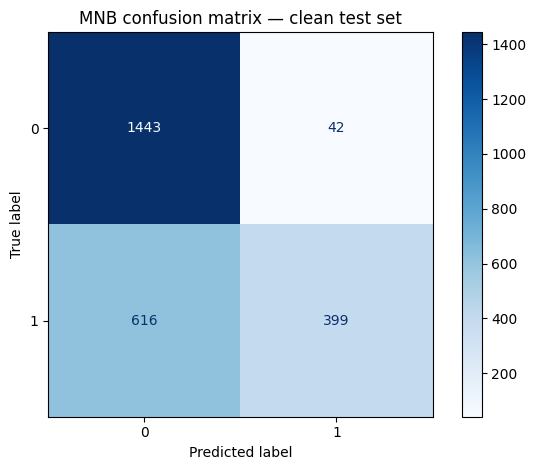

In [7]:
clean_predictions = prediction_frames[('Clean Sinhala', 'Clean Sinhala')]
print(classification_report(
    clean_predictions['label'], clean_predictions['prediction'], zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    clean_predictions['label'],
    clean_predictions['prediction'],
    labels=fitted_models['Clean Sinhala'].classes_,
    cmap='Blues',
)
plt.title('MNB confusion matrix — clean test set')
plt.tight_layout()
plt.show()

## Save model and run custom predictions

In [8]:
for condition, model in fitted_models.items():
    safe_condition = condition.lower().replace(' ', '_')
    model_path = RESULTS_DIR / f'mnb_{safe_condition}_pipeline.joblib'
    joblib.dump(model, model_path)
    print('Saved:', model_path)

def predict_texts(texts, condition='Clean Sinhala'):
    if condition not in fitted_models:
        raise ValueError(f'Unknown condition {condition!r}; choose from {list(fitted_models)}')
    model = fitted_models[condition]
    texts = pd.Series(texts, dtype='string').fillna('').astype(str)
    probabilities = model.predict_proba(texts)
    indices = probabilities.argmax(axis=1)
    return pd.DataFrame({
        'text': texts,
        'prediction': model.classes_[indices],
        'confidence': probabilities.max(axis=1),
    })

# Replace these examples with your own Sinhala or noisy text.
display(predict_texts(['example text']))

Saved: E:\nlp\Sinhala-Noisy-Hatespeech-Data\results\mnb\mnb_clean_sinhala_pipeline.joblib
Saved: E:\nlp\Sinhala-Noisy-Hatespeech-Data\results\mnb\mnb_transliteration_pipeline.joblib
Saved: E:\nlp\Sinhala-Noisy-Hatespeech-Data\results\mnb\mnb_code_mix_pipeline.joblib


,text,prediction,confidence
0,example text,1,0.539173
